# Notebook 2 — Modelling, Model Selection, Evaluation & Price What-If
**Customer Response Prediction & Pricing Intelligence — Aurevia (CRISP-ML(Q): Modelling → Evaluation)**

**Input:** `data/processed/model_table.csv` from Notebook 1 (call notes are not used).

| Step | What happens |
|---|---|
| A | Funnel **step 5**: keep only feature groups / features the model confirms on unseen data |
| B | **Model selection**: compare candidates with grouped, repeated CV and pick the best using a simplicity-aware rule |
| C | Hold-out test on the unseen season (2024-25), calibration, cut-off, check against the success criteria |
| D | Explainability: global drivers + top-3 reasons per account |
| E | Final model, scoring of 2025-26, and the **-5% … +5% price what-if** simulator |

Validation rules: (1) the hold-out season is touched **once**, after all choices are made; (2) CV folds are **grouped by customer** so the same account never sits in both train and validation.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import time, hashlib, datetime
import numpy as np, pandas as pd, joblib, matplotlib.pyplot as plt
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 220)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss, log_loss, roc_curve,
                             precision_recall_fscore_support, confusion_matrix)
from sklearn.model_selection import StratifiedGroupKFold, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from lightgbm import LGBMClassifier

SEED = 42
HOLDOUT, SCORE_SEASON = "2024-25", "2025-26"
PROCESSED_DIR = "../data/processed/"
N_SPLITS, N_REPEATS = 5, 3
BLUE, GREY, RED = "#0b4a77", "#9aa5b1", "#c0392b"

## 1. Load, feature groups, split

In [2]:
df = pd.read_csv(PROCESSED_DIR + "model_table.csv", parse_dates=["offer_date"])

GROUPS = {   # identical to Notebook 1
 "price":        ["price_vs_comp_pct", "discount_from_list_pct"],
 "competition":  ["is_incumbent", "comp_family", "log_prior_volume"],
 "account":      ["customer_type", "log_beds", "region", "has_buying_group", "relationship_years", "clin_ord"],
 "product":      ["product_id"],
 "engagement":   ["eng_n_interactions", "eng_n_issue_flags", "eng_n_clin_committee", "eng_days_since_contact", "eng_no_contact"],
 "interactions": ["price_x_incumbent"] + [c for c in df if c.startswith("price_x_type_")],
 "history":      ["hist_n_prior", "hist_win_rate_prior", "hist_last_outcome"],
}
CORE, OPTIONAL = ["price", "competition", "account", "product"], ["engagement", "interactions", "history"]
CAT = ["comp_family", "customer_type", "region", "product_id"]
LEAKY = ["final_negotiated_price_per_dose", "num_negotiation_rounds", "outcome_date", "outcome", "days_to_outcome"]
assert not {c for g in GROUPS.values() for c in g} & set(LEAKY), "leaky column!"
cols_of = lambda groups: [c for g in groups for c in GROUPS[g]]

lab     = df[df.dataset == "history"]
train   = lab[lab.season != HOLDOUT].reset_index(drop=True)
holdout = lab[lab.season == HOLDOUT].reset_index(drop=True)
score   = df[(df.dataset == "score") & (df.season == SCORE_SEASON)].reset_index(drop=True)
y_tr, y_ho = train.target.astype(int), holdout.target.astype(int)
g_tr = train.customer_id
print(f"train {len(train)} (win {y_tr.mean():.1%}) | holdout {len(holdout)} (win {y_ho.mean():.1%}) | to score {len(score)}")

train 704 (win 33.0%) | holdout 408 (win 38.5%) | to score 430


## 2. Pipelines, metrics, CV helpers
Imputation, encoding and scaling live **inside** the pipeline, so they are fitted on training folds only.
Class imbalance (35 % won) is handled with **class weights** (no synthetic data); probabilities are re-calibrated afterwards.

In [3]:
def make_pipe(model, cols, scale=False):
    num = [c for c in cols if c not in CAT]; cat = [c for c in cols if c in CAT]
    steps = [("impute", SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True))]
    if scale: steps.append(("scale", StandardScaler()))          # scaling only for linear models, fitted on training data only
    prep = ColumnTransformer([("num", Pipeline(steps), num),
                              ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat)], verbose_feature_names_out=False)
    return Pipeline([("prep", prep), ("clf", model)])

def ece(y, p, bins=10):
    edges = np.quantile(p, np.linspace(0, 1, bins + 1)); idx = np.clip(np.searchsorted(edges, p, side="right") - 1, 0, bins - 1)
    return sum((idx == b).mean() * abs(y[idx == b].mean() - p[idx == b].mean()) for b in range(bins) if (idx == b).any())

def metrics(y, p):
    y, p = np.asarray(y), np.clip(np.asarray(p), 1e-6, 1 - 1e-6); top = np.argsort(-p)[: max(1, len(p) // 10)]
    return {"roc_auc": roc_auc_score(y, p), "pr_auc": average_precision_score(y, p), "brier": brier_score_loss(y, p),
            "log_loss": log_loss(y, p), "calib_error": ece(y, p), "lift_top10": y[top].mean() / y.mean()}

def cv_oof(pipe, X, y, groups, repeats=N_REPEATS):
    # grouped repeated CV -> list of out-of-fold predictions (one array per repeat) and per-fold AUCs
    oofs, fold_auc = [], []
    for r in range(repeats):
        oof = np.zeros(len(y))
        for tr, va in StratifiedGroupKFold(N_SPLITS, shuffle=True, random_state=SEED + r).split(X, y, groups):
            oof[va] = clone(pipe).fit(X.iloc[tr], y.iloc[tr]).predict_proba(X.iloc[va])[:, 1]
            fold_auc.append(roc_auc_score(y.iloc[va], oof[va]))
        oofs.append(oof)
    return oofs, np.array(fold_auc)

def delta_ci(y, p1, p0, n=1000, seed=0):
    rng = np.random.default_rng(seed); y = np.asarray(y); d = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() != y[i].max(): d.append(roc_auc_score(y[i], p1[i]) - roc_auc_score(y[i], p0[i]))
    return roc_auc_score(y, p1) - roc_auc_score(y, p0), np.percentile(d, 2.5), np.percentile(d, 97.5)

LOGIT = lambda C=0.3: LogisticRegression(C=C, max_iter=3000, class_weight="balanced")

# Step A — Funnel step 5: which features does the model confirm?
Probe model: regularised logistic regression (simple, stable on 700 rows). For each candidate group we compare **grouped-CV AUC** against the core set (price, competition, account, product).
A group is kept only if the **95 % bootstrap interval of the AUC gain is above zero**; otherwise it adds noise.
(The out-of-fold predictions are averaged over the 3 repeats; gain = AUC with group − AUC core.)

In [4]:
def probe(group_list):
    cols = cols_of(group_list); X = train[cols]
    oofs, folds = cv_oof(make_pipe(LOGIT(), cols, scale=True), X, y_tr, g_tr)
    return np.mean(oofs, axis=0), np.mean(folds)

p_core, auc_core = probe(CORE)
rows = [dict(feature_set="core only", n_features=len(cols_of(CORE)), cv_auc=auc_core, gain=0.0, ci_low=np.nan, ci_high=np.nan, keep="(baseline)")]
probes = {}
for g in OPTIONAL + ["ALL optional"]:
    gl = CORE + (OPTIONAL if g == "ALL optional" else [g])
    p, a = probe(gl); d, lo, hi = delta_ci(y_tr, p, p_core)
    rows.append(dict(feature_set="core + " + g, n_features=len(cols_of(gl)), cv_auc=a, gain=d, ci_low=lo, ci_high=hi, keep=("YES" if lo > 0 else "no")))
    probes[g] = lo > 0
ablation = pd.DataFrame(rows); ablation.round(3)

,feature_set,n_features,cv_auc,gain,ci_low,ci_high,keep
0,core only,12,0.662,0.000,NaN,NaN,(baseline)
1,core + engagement,17,0.656,-0.006,-0.017,0.006,no
2,core + interactions,17,0.660,-0.002,-0.009,0.005,no
3,core + history,15,0.667,0.007,-0.006,0.020,no
4,core + ALL optional,25,0.657,-0.003,-0.020,0.013,no


In [5]:
KEEP_GROUPS = CORE + [g for g in OPTIONAL if probes[g]]
print("Feature groups used by the model:", KEEP_GROUPS)

# Feature-level checks the deck flagged: tenure & clinical influence "kept only if the model confirms value"; prior volume overlaps incumbency
FEATURES = cols_of(KEEP_GROUPS)
p_full, _ = probe(KEEP_GROUPS)
drop_rows, dropped = [], []
for f in ["relationship_years", "clin_ord", "log_prior_volume"]:
    cols = [c for c in FEATURES if c != f]
    oofs, _ = cv_oof(make_pipe(LOGIT(), cols, scale=True), train[cols], y_tr, g_tr)
    d, lo, hi = delta_ci(y_tr, p_full, np.mean(oofs, axis=0))          # value of keeping f
    drop_rows.append(dict(feature=f, auc_gain_from_keeping=d, ci_low=lo, ci_high=hi, decision="keep" if lo > 0 else "drop (no confirmed value)"))
    if lo <= 0: dropped.append(f)
display(pd.DataFrame(drop_rows).round(3))
FEATURES = [c for c in FEATURES if c not in dropped]
print(f"\nFINAL FEATURE SET: {len(FEATURES)} features ->", FEATURES)

Feature groups used by the model: ['price', 'competition', 'account', 'product']


,feature,auc_gain_from_keeping,ci_low,ci_high,decision
0,relationship_years,0.001,-0.010,0.009,drop (no confirmed value)
1,clin_ord,-0.004,-0.013,0.005,drop (no confirmed value)
2,log_prior_volume,-0.001,-0.004,0.002,drop (no confirmed value)



FINAL FEATURE SET: 9 features -> ['price_vs_comp_pct', 'discount_from_list_pct', 'is_incumbent', 'comp_family', 'customer_type', 'log_beds', 'region', 'has_buying_group', 'product_id']


# Step B — Model selection
**Candidates** (all use class weights where supported): baseline prior · logistic L2 · logistic L1 (sparse) · random forest · gradient boosting · LightGBM · LightGBM tuned (randomised search with the same grouped CV).

**Selection rule — "one-standard-error, simplest wins":**
1. Rank by mean grouped-CV ROC-AUC.
2. Take every model whose AUC is within **one standard error** of the best.
3. Among those, choose the **simplest/most explainable** (field users must understand the reasons). A complex model must *clearly* beat a simple one to be chosen.

The hold-out season plays **no part** in this choice.

In [6]:
X_tr = train[FEATURES]
COMPLEXITY = {"baseline (prior rate)": 0, "logistic L1": 1, "logistic L2": 2, "random forest": 4, "gradient boosting": 4, "lightgbm": 5, "lightgbm (tuned)": 5}
LGB = dict(n_estimators=300, learning_rate=0.03, num_leaves=8, min_child_samples=20, subsample=0.8, subsample_freq=1,
           colsample_bytree=0.7, reg_lambda=5.0, class_weight="balanced", random_state=SEED, verbose=-1, n_jobs=1)
candidates = {
 "baseline (prior rate)": make_pipe(DummyClassifier(strategy="prior"), FEATURES),
 "logistic L2":       make_pipe(LOGIT(0.3), FEATURES, scale=True),
 "logistic L1":       make_pipe(LogisticRegression(penalty="l1", solver="liblinear", C=0.2, max_iter=3000, class_weight="balanced"), FEATURES, scale=True),
 "random forest":     make_pipe(RandomForestClassifier(n_estimators=400, min_samples_leaf=10, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED), FEATURES),
 "gradient boosting": make_pipe(HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=150, min_samples_leaf=20, class_weight="balanced", random_state=SEED), FEATURES),
 "lightgbm":          make_pipe(LGBMClassifier(**LGB), FEATURES),
}
# tuned LightGBM: randomised search, same grouped CV, train seasons only
splits = list(StratifiedGroupKFold(N_SPLITS, shuffle=True, random_state=SEED).split(X_tr, y_tr, g_tr))
space = {"clf__n_estimators": [100, 200, 300, 400], "clf__learning_rate": [0.01, 0.02, 0.03, 0.05], "clf__num_leaves": [4, 6, 8, 12, 16],
         "clf__min_child_samples": [10, 20, 30, 40, 60], "clf__subsample": [0.6, 0.8, 1.0], "clf__colsample_bytree": [0.4, 0.6, 0.8, 1.0],
         "clf__reg_lambda": [0.5, 2, 5, 10, 30], "clf__reg_alpha": [0, 0.5, 1, 3]}
search = RandomizedSearchCV(clone(candidates["lightgbm"]), space, n_iter=25, scoring="roc_auc", cv=splits, random_state=SEED, n_jobs=1).fit(X_tr, y_tr)
candidates["lightgbm (tuned)"] = search.best_estimator_
print("tuned LightGBM params:", {k.replace("clf__", ""): v for k, v in search.best_params_.items()})

tuned LightGBM params: {'subsample': 1.0, 'reg_lambda': 2, 'reg_alpha': 0.5, 'num_leaves': 4, 'n_estimators': 100, 'min_child_samples': 60, 'learning_rate': 0.01, 'colsample_bytree': 1.0}


In [7]:
rows, oof_store = [], {}
for name, pipe in candidates.items():
    t0 = time.time(); oofs, folds = cv_oof(pipe, X_tr, y_tr, g_tr)
    m = pd.DataFrame([metrics(y_tr, o) for o in oofs]).mean()
    rows.append(dict(model=name, complexity=COMPLEXITY[name], auc=folds.mean(), auc_se=folds.std(ddof=1) / np.sqrt(N_SPLITS),
                     pr_auc=m.pr_auc, lift_top10=m.lift_top10, fit_s=round(time.time() - t0, 1)))
    oof_store[name] = oofs
sel = pd.DataFrame(rows).sort_values("auc", ascending=False).reset_index(drop=True)
sel.round(3)

,model,complexity,auc,auc_se,pr_auc,lift_top10,fit_s
0,lightgbm (tuned),5,0.691,0.022,0.505,1.980,0.7
1,logistic L1,1,0.686,0.018,0.541,2.066,0.6
2,logistic L2,2,0.663,0.017,0.518,2.037,0.7
3,random forest,4,0.643,0.019,0.481,1.850,16.2
4,gradient boosting,4,0.628,0.019,0.471,1.835,3.8
5,lightgbm,5,0.627,0.020,0.463,1.676,1.2
6,baseline (prior rate),0,0.500,0.000,0.326,0.925,0.5


Best AUC: lightgbm (tuned) = 0.691 (SE 0.022) -> models within 1 SE: ['logistic L1', 'lightgbm (tuned)']
CHOSEN (simplest within 1 SE): logistic L1


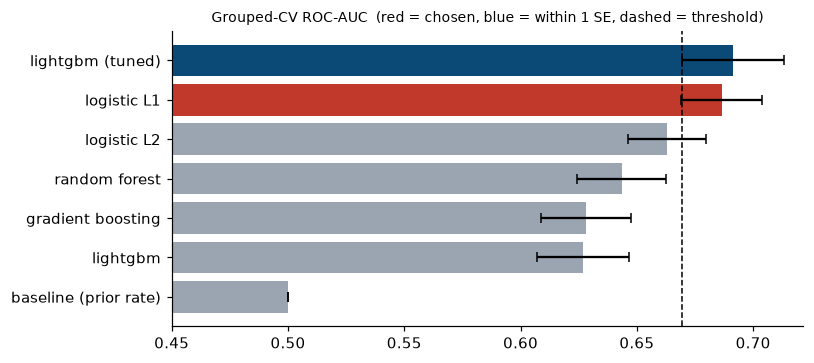

In [8]:
real = sel[sel.model != "baseline (prior rate)"]
best = real.iloc[0]; threshold = best.auc - best.auc_se
eligible = real[real.auc >= threshold].sort_values(["complexity", "auc"], ascending=[True, False])
CHOSEN = eligible.iloc[0].model
sel["within_1SE_of_best"] = sel.auc >= threshold; sel["chosen"] = sel.model == CHOSEN
print(f"Best AUC: {best.model} = {best.auc:.3f} (SE {best.auc_se:.3f}) -> models within 1 SE: {list(eligible.model)}")
print(f"CHOSEN (simplest within 1 SE): {CHOSEN}")
sel.to_csv(PROCESSED_DIR + "model_selection.csv", index=False)

fig, ax = plt.subplots(figsize=(7.5, 3.4)); s = sel.iloc[::-1]
ax.barh(s.model, s.auc, xerr=s.auc_se, color=[RED if c else (BLUE if w else GREY) for c, w in zip(s.chosen, s.within_1SE_of_best)], capsize=3)
ax.axvline(threshold, color="k", ls="--", lw=1); ax.set_xlim(0.45, max(0.72, s.auc.max() + 0.03))
ax.set_title("Grouped-CV ROC-AUC  (red = chosen, blue = within 1 SE, dashed = threshold)", fontsize=9); plt.tight_layout(); plt.show()

# Step C — Hold-out test on the unseen season (touched once)
Fit the chosen model on 2022-24, **calibrate** (sigmoid, grouped splits) and test on 2024-25 — exactly how 2025-26 will be scored.

In [9]:
chosen_pipe = candidates[CHOSEN]
X_ho = holdout[FEATURES]
raw = clone(chosen_pipe).fit(X_tr, y_tr)
cal = CalibratedClassifierCV(clone(chosen_pipe), method="sigmoid", cv=splits).fit(X_tr, y_tr)
base = clone(candidates["baseline (prior rate)"]).fit(X_tr, y_tr)
hold = pd.DataFrame({"baseline": metrics(y_ho, base.predict_proba(X_ho)[:, 1]),
                     f"{CHOSEN} (raw, class-weighted)": metrics(y_ho, raw.predict_proba(X_ho)[:, 1]),
                     f"{CHOSEN} (calibrated)": metrics(y_ho, cal.predict_proba(X_ho)[:, 1])}).T
hold.round(3)

,roc_auc,pr_auc,brier,log_loss,calib_error,lift_top10
baseline,0.500,0.385,0.240,0.673,0.055,0.780
"logistic L1 (raw, class-weighted)",0.683,0.565,0.242,0.685,0.164,1.689
logistic L1 (calibrated),0.683,0.562,0.215,0.620,0.055,1.689


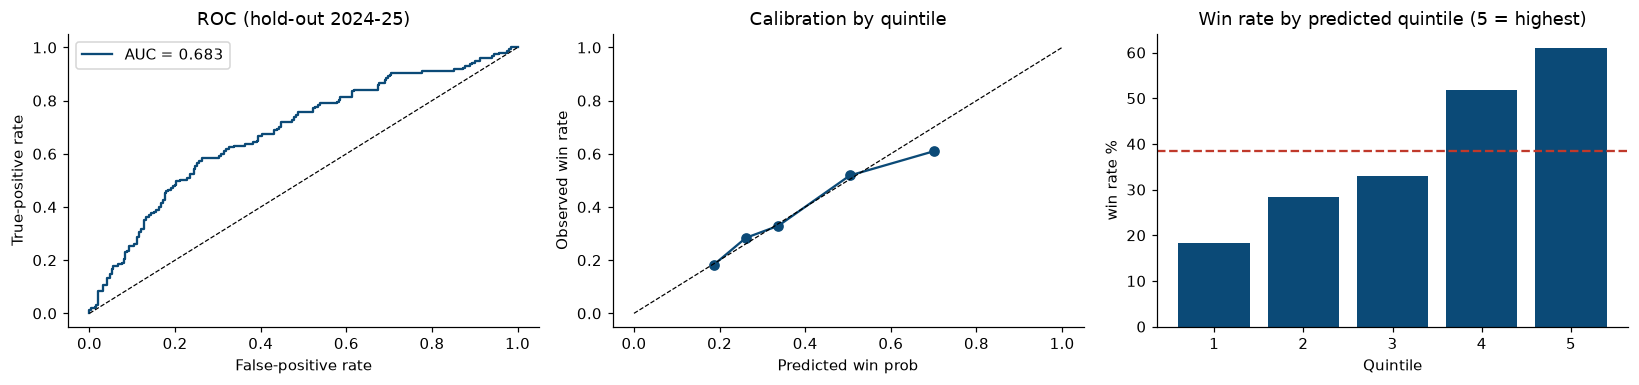

,n,predicted,actual,gap_pts
quintile,,,,
1,82,0.187,0.183,-0.366
2,81,0.261,0.284,2.261
3,82,0.337,0.329,-0.778
4,81,0.504,0.519,1.425
5,82,0.700,0.610,-9.070


In [10]:
p_ho = cal.predict_proba(X_ho)[:, 1]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
fpr, tpr, _ = roc_curve(y_ho, p_ho); ax[0].plot(fpr, tpr, color=BLUE, label=f"AUC = {roc_auc_score(y_ho, p_ho):.3f}"); ax[0].plot([0, 1], [0, 1], "k--", lw=.8)
ax[0].set(title="ROC (hold-out 2024-25)", xlabel="False-positive rate", ylabel="True-positive rate"); ax[0].legend()
q = pd.DataFrame({"y": y_ho, "p": p_ho}); q["quintile"] = pd.qcut(q.p.rank(method="first"), 5, labels=[1, 2, 3, 4, 5])
cal_tbl = q.groupby("quintile", observed=True).agg(n=("y", "size"), predicted=("p", "mean"), actual=("y", "mean")); cal_tbl["gap_pts"] = (cal_tbl.actual - cal_tbl.predicted) * 100
ax[1].plot(cal_tbl.predicted, cal_tbl.actual, "o-", color=BLUE); ax[1].plot([0, 1], [0, 1], "k--", lw=.8); ax[1].set(title="Calibration by quintile", xlabel="Predicted win prob", ylabel="Observed win rate")
ax[2].bar(cal_tbl.index.astype(int), cal_tbl.actual * 100, color=BLUE); ax[2].axhline(y_ho.mean() * 100, color=RED, ls="--"); ax[2].set(title="Win rate by predicted quintile (5 = highest)", xlabel="Quintile", ylabel="win rate %")
plt.tight_layout(); plt.show(); cal_tbl.round(3)

In [11]:
# Cut-off for a "win" call: tuned on out-of-fold predictions of the TRAIN seasons only (never on the hold-out)
oof_cal = np.zeros(len(y_tr))
for tr, va in splits:
    m = CalibratedClassifierCV(clone(chosen_pipe), method="sigmoid", cv=3).fit(X_tr.iloc[tr], y_tr.iloc[tr]); oof_cal[va] = m.predict_proba(X_tr.iloc[va])[:, 1]
grid = np.linspace(0.15, 0.7, 56)
f1 = [precision_recall_fscore_support(y_tr, oof_cal >= t, average="binary", zero_division=0)[2] for t in grid]
CUTOFF = float(grid[int(np.argmax(f1))])
LO_CUT, HI_CUT = 0.25, 0.50          # business-readable risk tiers on the calibrated win probability (adjust to taste)
pr, rc, f, _ = precision_recall_fscore_support(y_ho, p_ho >= CUTOFF, average="binary", zero_division=0)
print(f"Win-call cut-off (max F1 on train OOF): {CUTOFF:.2f} | tiers: At risk < {LO_CUT:.2f} <= Contested < {HI_CUT:.2f} <= Likely win")
print(f"Hold-out at that cut-off: precision {pr:.2f} | recall {rc:.2f} | F1 {f:.2f}")
print(pd.DataFrame(confusion_matrix(y_ho, p_ho >= CUTOFF), index=["actual LOST", "actual WON"], columns=["pred LOST", "pred WON"]))
tiers = pd.cut(p_ho, [-1, LO_CUT, HI_CUT, 2], labels=["At risk", "Contested", "Likely win"])
print("\nHold-out win rate by tier:"); print(pd.DataFrame({"y": y_ho.values, "tier": tiers}).groupby("tier", observed=True)["y"].agg(["size", "mean"]).round(3).to_string())

Win-call cut-off (max F1 on train OOF): 0.25 | tiers: At risk < 0.25 <= Contested < 0.50 <= Likely win
Hold-out at that cut-off: precision 0.44 | recall 0.84 | F1 0.58
             pred LOST  pred WON
actual LOST         82       169
actual WON          25       132

Hold-out win rate by tier:
            size   mean
tier                   
At risk      107  0.234
Contested    180  0.328
Likely win   121  0.603


## Check against the success criteria

In [12]:
h = hold.iloc[2]
crit = pd.DataFrame([
 ("ROC-AUC on an unseen season",           ">= 0.70",       f"{h.roc_auc:.3f}",      "MET" if h.roc_auc >= 0.70 else "NOT MET - signal in offer-time data is moderate"),
 ("Calibration: max |gap| per quintile",   "within +/-5 pts", f"{cal_tbl.gap_pts.abs().max():.1f} pts", "MET" if cal_tbl.gap_pts.abs().max() <= 5 else "NOT MET"),
 ("Calibration: mean |gap|",               "(info)",        f"{cal_tbl.gap_pts.abs().mean():.1f} pts", ""),
 ("Lift in top decile vs. average",        "(info)",        f"{h.lift_top10:.2f}x",   ""),
 ("Brier vs. baseline",                    "lower is better", f"{h.brier:.3f} vs {hold.iloc[0].brier:.3f}", "better" if h.brier < hold.iloc[0].brier else "not better"),
], columns=["criterion", "target", "result", "status"])
crit

,criterion,target,result,status
0,ROC-AUC on an unseen season,>= 0.70,0.683,NOT MET - signal in offer-time data is moderate
1,Calibration: max |gap| per quintile,within +/-5 pts,9.1 pts,NOT MET
2,Calibration: mean |gap|,(info),2.8 pts,
3,Lift in top decile vs. average,(info),1.69x,
4,Brier vs. baseline,lower is better,0.215 vs 0.240,better


# Step D — What drives the prediction?
Global importance uses **permutation importance on the hold-out** (model-agnostic: how much AUC is lost if a feature is shuffled).

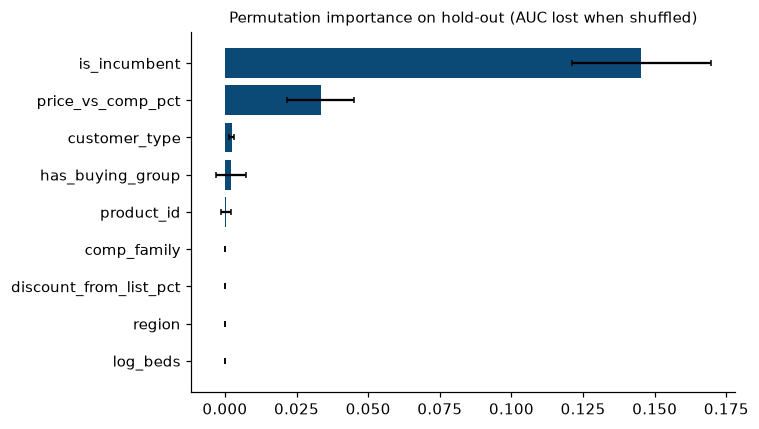

,feature,auc_drop,sd
2,is_incumbent,0.1454,0.0242
0,price_vs_comp_pct,0.0334,0.0116
4,customer_type,0.0024,0.0009
7,has_buying_group,0.0021,0.0051
8,product_id,0.0005,0.0017
3,comp_family,0.0000,0.0000
1,discount_from_list_pct,0.0000,0.0000
6,region,0.0000,0.0000
5,log_beds,0.0000,0.0000


In [13]:
pi = permutation_importance(raw, X_ho, y_ho, scoring="roc_auc", n_repeats=30, random_state=SEED, n_jobs=1)
imp = pd.DataFrame({"feature": FEATURES, "auc_drop": pi.importances_mean, "sd": pi.importances_std}).sort_values("auc_drop", ascending=False)
top = imp.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4)); ax.barh(top.feature, top.auc_drop, xerr=top.sd, color=BLUE, capsize=2)
ax.set_title("Permutation importance on hold-out (AUC lost when shuffled)", fontsize=10); plt.tight_layout(); plt.show()
imp.head(12).round(4)

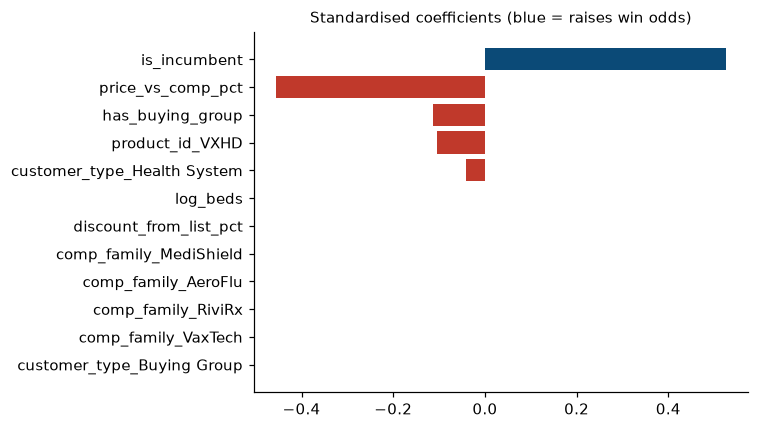

In [14]:
if CHOSEN.startswith("logistic"):
    names = raw.named_steps["prep"].get_feature_names_out(); coef = pd.Series(raw.named_steps["clf"].coef_[0], index=names)
    c = coef.reindex(coef.abs().sort_values(ascending=False).index).head(12).iloc[::-1]
    fig, ax = plt.subplots(figsize=(7, 4)); ax.barh(c.index, c.values, color=[BLUE if v > 0 else RED for v in c.values])
    ax.set_title("Standardised coefficients (blue = raises win odds)", fontsize=10); plt.tight_layout(); plt.show()

## Step D2 — Is price sensitivity really different by segment?
The EDA showed large raw win-rate gaps (e.g. buying groups gain ~30 pts from pricing at/below the competitor). But incumbents and some customer types simply win more at *any* price. The proper test is on the log-odds scale: does the **slope** of price differ by segment?
Likelihood-ratio tests below compare a model with a common price slope against one with segment-specific slopes (all labelled seasons). Needs `statsmodels` (`%pip install statsmodels` if missing).

In [16]:
import statsmodels.api as sm
from scipy import stats
d = lab.copy(); d["y"] = d.target.astype(int); d["gap"] = d.price_vs_comp_pct
TYPES = ["Health System", "Independent Hospital", "IDN", "Buying Group"]
base = pd.concat([d[["gap", "is_incumbent"]], pd.get_dummies(d.customer_type, drop_first=True).astype(float)], axis=1)
m0 = sm.Logit(d.y, sm.add_constant(base)).fit(disp=0)

def lr_test(extra, label):
    m1 = sm.Logit(d.y, sm.add_constant(base.assign(**extra))).fit(disp=0); stat = 2 * (m1.llf - m0.llf)
    return dict(test=label, chi2=round(stat, 2), df=len(extra), p_value=round(stats.chi2.sf(stat, len(extra)), 3))
tests = pd.DataFrame([
  lr_test({"g_inc": d.gap * d.is_incumbent}, "price slope differs: incumbent vs displacement"),
  lr_test({f"g_{t}": d.gap * (d.customer_type == t).astype(float) for t in TYPES[1:]}, "price slope differs: by customer type")])
tests["verdict"] = np.where(tests.p_value < 0.05, "confirmed", "NOT confirmed (p >= 0.05)")
display(tests)

rows = []
for label, mask in [("Aurevia incumbent", d.is_incumbent == 1), ("Displacement", d.is_incumbent == 0)] + [(t, d.customer_type == t) for t in TYPES]:
    s_ = d[mask]; m = sm.Logit(s_.y, sm.add_constant(s_[["gap"]])).fit(disp=0); b, se = m.params["gap"], m.bse["gap"]; p0 = s_.y.mean()
    rows.append(dict(segment=label, n=len(s_), base_win_rate=round(p0, 3), slope_per_1pt=round(b, 3), se=round(se, 3),
                     approx_gain_pts_for_5pct_cut=round(p0 * (1 - p0) * -b * 5 * 100, 1)))
display(pd.DataFrame(rows))
print("Reading: slopes are similar once base win rates are accounted for. Buying groups look steeper but the difference is not statistically confirmed (n is small).")
print("-> the model keeps ONE common price slope; segment curves in the what-if differ in LEVEL (incumbency, type), not in steepness.")

,test,chi2,df,p_value,verdict
0,price slope differs: incumbent vs displacement,0.39,1,0.531,NOT confirmed (p >= 0.05)
1,price slope differs: by customer type,4.25,3,0.236,NOT confirmed (p >= 0.05)


,segment,n,base_win_rate,slope_per_1pt,se,approx_gain_pts_for_5pct_cut
0,Aurevia incumbent,220,0.618,-0.053,0.024,6.3
1,Displacement,892,0.284,-0.072,0.013,7.3
2,Health System,433,0.300,-0.056,0.018,5.9
3,Independent Hospital,376,0.378,-0.045,0.018,5.2
4,IDN,224,0.379,-0.067,0.025,7.9
5,Buying Group,79,0.405,-0.146,0.050,17.6


Reading: slopes are similar once base win rates are accounted for. Buying groups look steeper but the difference is not statistically confirmed (n is small).
-> the model keeps ONE common price slope; segment curves in the what-if differ in LEVEL (incumbency, type), not in steepness.


# Step E — Final model, scoring 2025-26 and the price what-if
Refit on **all** labelled seasons (2022-25), calibrate, score the 430 open opportunities, attach the **top reasons** for each, and re-score every deal at price changes of -5 % … +5 %.

> **Interpretation warning:** past prices were set by Aurevia, not randomly tested. The what-if curve therefore shows *association in history*, not a guaranteed causal effect. A person approves every price.

In [17]:
lab_all = pd.concat([train, holdout], ignore_index=True)
X_all, y_all, g_all = lab_all[FEATURES], lab_all.target.astype(int), lab_all.customer_id
final_splits = list(StratifiedGroupKFold(N_SPLITS, shuffle=True, random_state=SEED).split(X_all, y_all, g_all))
final_base  = clone(chosen_pipe).fit(X_all, y_all)                                                   # used for explanations
final_model = CalibratedClassifierCV(clone(chosen_pipe), method="sigmoid", cv=final_splits).fit(X_all, y_all)   # used for probabilities

# ---- price what-if: rebuild every price-derived feature from raw prices ----
def add_price_features(d, move=0.0):
    offer = d["initial_offered_price_per_dose"] * (1 + move); d = d.copy()
    d["price_vs_comp_pct"]      = (offer / d["competitor_price_estimate_per_dose"] - 1) * 100
    d["discount_from_list_pct"] = (1 - offer / d["list_price_per_dose"]) * 100
    d["price_x_incumbent"]      = d["price_vs_comp_pct"] * d["is_incumbent"]
    for t in ["Health System", "Independent Hospital", "IDN", "Buying Group"]:
        d["price_x_type_" + t.replace(" ", "_")] = d["price_vs_comp_pct"] * (d["customer_type"] == t)
    return d

RAWP = {"sim_offer_price": "initial_offered_price_per_dose", "sim_comp_price": "competitor_price_estimate_per_dose", "sim_list_price": "list_price_per_dose"}
def rescore(rows, move=0.0, model=final_model):
    d = add_price_features(rows.rename(columns=RAWP), move)
    return model.predict_proba(d[FEATURES])[:, 1]

# consistency check: re-pricing by 0% must reproduce the stored features exactly
chk = add_price_features(score.rename(columns=RAWP), 0.0)
assert np.allclose(chk[[c for c in FEATURES if c.startswith(("price_", "discount_"))]], score[[c for c in FEATURES if c.startswith(("price_", "discount_"))]], atol=1e-6)

MOVES = [-0.05, -0.025, 0.0, 0.025, 0.05]
for mv in MOVES: score[f"p_{mv:+.1%}"] = rescore(score, mv)
score["win_probability"] = score["p_+0.0%"]
score["gain_from_5pct_cut"] = score["p_-5.0%"] - score["win_probability"]
print(score[["win_probability", "gain_from_5pct_cut"]].describe().round(3).T)

                    count   mean    std    min    25%    50%    75%    max
win_probability     430.0  0.410  0.178  0.072  0.266  0.350  0.587  0.786
gain_from_5pct_cut  430.0  0.068  0.008  0.031  0.064  0.069  0.073  0.092


In [18]:
# ---- top-3 reasons per opportunity ----
def reasons(pipe, X, k=3):
    prep, clf = pipe.named_steps["prep"], pipe.named_steps["clf"]
    Xt = prep.transform(X); Xt = Xt.toarray() if hasattr(Xt, "toarray") else np.asarray(Xt); names = list(prep.get_feature_names_out())
    if isinstance(clf, LogisticRegression):
        contrib = Xt * clf.coef_[0]                                  # additive log-odds contributions (centred by the scaler)
    else:
        import shap
        v = shap.TreeExplainer(clf).shap_values(Xt); v = v[1] if isinstance(v, list) else np.asarray(v); contrib = v[:, :, 1] if v.ndim == 3 else v
    fmt = lambda idx, row: "; ".join(f"{names[i]} ({row[i]:+.2f})" for i in idx)
    up, dn = [], []
    for row in contrib:
        o = np.argsort(row); dn.append(fmt([i for i in o[:k] if row[i] < -0.02], row)); up.append(fmt([i for i in o[::-1][:k] if row[i] > 0.02], row))
    return up, dn
score["drivers_for_win"], score["drivers_against_win"] = reasons(final_base, score[FEATURES])

gain_hi = score.gain_from_5pct_cut.quantile(0.67)
def action(r):
    if r.win_probability >= HI_CUT and r.gain_from_5pct_cut < gain_hi: return "Protect: likely win, hold price"
    if r.gain_from_5pct_cut >= gain_hi and r.win_probability < HI_CUT: return "Price-responsive: a discount can move the odds"
    if r.win_probability < LO_CUT: return "Long shot: use non-price levers / executive sponsor"
    return "Monitor"
score["recommendation"] = score.apply(action, axis=1)
score["risk_tier"] = pd.cut(score.win_probability, [-1, LO_CUT, HI_CUT, 2], labels=["At risk", "Contested", "Likely win"])
print(score.recommendation.value_counts().to_string()); print(); print(score.risk_tier.value_counts().to_string())

recommendation
Monitor                                                167
Price-responsive: a discount can move the odds          88
Protect: likely win, hold price                         88
Long shot: use non-price levers / executive sponsor     87

risk_tier
Contested     201
Likely win    142
At risk        87


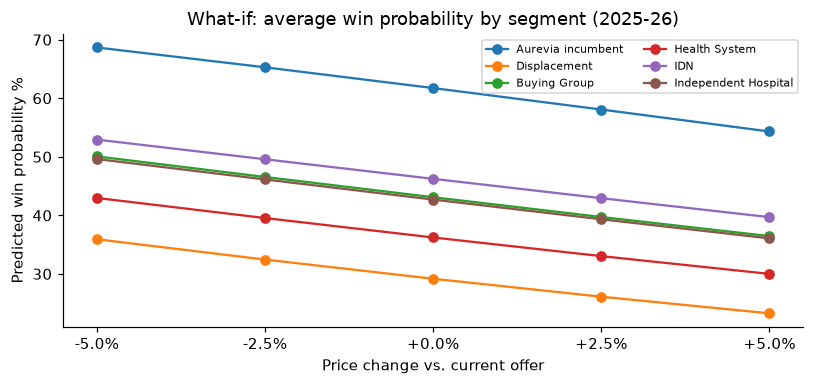

,-5.0%,-2.5%,+0.0%,+2.5%,+5.0%
Aurevia incumbent,68.7,65.3,61.7,58.1,54.3
Displacement,35.9,32.5,29.2,26.1,23.3
Buying Group,50.1,46.6,43.1,39.7,36.5
Health System,43.0,39.5,36.2,33.0,30.0
IDN,52.9,49.6,46.2,42.9,39.7
Independent Hospital,49.6,46.1,42.7,39.3,36.1


In [19]:
# ---- what-if curves by segment ----
score["segment"] = np.where(score.is_incumbent == 1, "Aurevia incumbent", "Displacement")
curve = pd.concat([score.groupby("segment")[[f"p_{m:+.1%}" for m in MOVES]].mean(), score.groupby("customer_type")[[f"p_{m:+.1%}" for m in MOVES]].mean()])
curve.columns = [f"{m:+.1%}" for m in MOVES]
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for name, r in curve.iterrows(): ax.plot(MOVES, r.values * 100, marker="o", label=name)
ax.set(xlabel="Price change vs. current offer", ylabel="Predicted win probability %", title="What-if: average win probability by segment (2025-26)")
ax.set_xticks(MOVES); ax.set_xticklabels([f"{m:+.1%}" for m in MOVES]); ax.legend(fontsize=7, ncol=2); plt.tight_layout(); plt.show()
(curve * 100).round(1)

In [20]:
def simulate(opportunity_id, moves=(-0.05, -0.025, 0.0, 0.025, 0.05)):
    r = score[score.opportunity_id == opportunity_id]; assert len(r), "opportunity_id not found"
    return pd.DataFrame([dict(price_change=f"{m:+.1%}", price_per_dose=round(r.sim_offer_price.iloc[0] * (1 + m), 2), win_probability=round(rescore(r, m)[0], 3)) for m in moves])

ex = score.sort_values("gain_from_5pct_cut", ascending=False).opportunity_id.iloc[0]
print("Example what-if for", ex, "-", score.loc[score.opportunity_id == ex, ["customer_name", "product_name", "customer_type", "segment"]].iloc[0].to_dict())
simulate(ex)

Example what-if for OPP001399 - {'customer_name': 'Cascade Fairview Memorial Hospital', 'product_name': 'Immunexa', 'customer_type': 'Independent Hospital', 'segment': 'Aurevia incumbent'}


,price_change,price_per_dose,win_probability
0,-5.0%,81.49,0.484
1,-2.5%,83.64,0.438
2,+0.0%,85.78,0.392
3,+2.5%,87.92,0.349
4,+5.0%,90.07,0.308


## Save outputs
Every output is stamped with a **model version** and a **data version** (hash of the training table).

In [21]:
data_version = hashlib.md5(pd.util.hash_pandas_object(lab_all[FEATURES + ["target"]], index=False).values.tobytes()).hexdigest()[:10]
model_version = f"{CHOSEN.replace(' ', '_')}_{datetime.date.today():%Y%m%d}"
out_cols = ["opportunity_id", "customer_id", "customer_name", "product_name", "incumbent_supplier", "customer_type", "sim_offer_price", "price_vs_comp_pct",
            "win_probability", "risk_tier", "gain_from_5pct_cut", "recommendation", "drivers_for_win", "drivers_against_win"] + [f"p_{m:+.1%}" for m in MOVES]
scored = score[out_cols].round(3).assign(model_version=model_version, data_version=data_version)
scored.to_csv(PROCESSED_DIR + "predictions_2025_26.csv", index=False)
joblib.dump({"model": final_model, "explainer_pipeline": final_base, "features": FEATURES, "cutoff": CUTOFF, "tier_bounds": (LO_CUT, HI_CUT),
             "model_version": model_version, "data_version": data_version}, PROCESSED_DIR + "final_model.joblib")
print("saved predictions_2025_26.csv, model_selection.csv, final_model.joblib |", model_version, "|", data_version)
scored.sort_values("win_probability").head(6)[["customer_name", "product_name", "win_probability", "recommendation", "drivers_against_win"]]

saved predictions_2025_26.csv, model_selection.csv, final_model.joblib | logistic_L1_20261117 | 1ac101ed85


,customer_name,product_name,win_probability,recommendation,drivers_against_win
387,Coastal Health Alliance — South Div.,Immunexa,0.072,Long shot: use non-price levers / executive sp...,price_vs_comp_pct (-1.72); is_incumbent (-0.28...
359,Highland Maple General Hospital,Vaxora HD,0.113,Long shot: use non-price levers / executive sp...,price_vs_comp_pct (-1.14); is_incumbent (-0.28...
409,Meridian Fairview General Hospital,Immunexa,0.114,Long shot: use non-price levers / executive sp...,price_vs_comp_pct (-0.98); is_incumbent (-0.28...
344,Beacon Summit Memorial Hospital,Vaxora Standard,0.127,Long shot: use non-price levers / executive sp...,price_vs_comp_pct (-0.89); is_incumbent (-0.28...
390,Northlake Health Network — North Div.,Immunexa,0.132,Long shot: use non-price levers / executive sp...,price_vs_comp_pct (-1.10); is_incumbent (-0.28...
270,Summit Pine Health Alliance,Vaxora HD,0.138,Long shot: use non-price levers / executive sp...,price_vs_comp_pct (-0.70); is_incumbent (-0.28...


## Summary
* **Features:** only offer-time information; each optional group had to prove its value on unseen data (Step A table).
* **Model choice:** the simplest model within one standard error of the best grouped-CV AUC (Step B), not the highest number on the hold-out.
* **Honest performance:** compare the hold-out AUC with the 0.70 target in the criteria table. Offer-time data supports a *moderate* ranking signal; the leaky ~0.9 seen in the EDA must never be quoted.
* **Segments:** segment differences in price *steepness* are not statistically confirmed (Step D2); buying groups are a hypothesis to test with more data or a pricing experiment.
* **Use:** probabilities are calibrated, so they can drive the what-if. The what-if shows historical association only; a person approves each price.
* **Next:** with sponsor inputs on volume and margin, convert gains from the what-if into value (extra wins × doses × net price); monitor calibration and contact-coverage drift by season.